In [7]:
# SECTION 1: IMPORT NESSEARY LIBRARIES

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [8]:
# SECTION 2: LOAD DATASET

df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [9]:
# SECTION 3: UNDERWSTAND DATASET

print("Dataset shape:", df.shape)
print("\nColumn name:", df.columns.tolist())
print("\nData types:", df.dtypes)
print("\nMissing values:", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nStatistical summary:", df.describe())

# SECTION 4: TARGET DISTRIBUTION

print("\nSurvival counts:", df["survived"].value_counts())
print("\nSurvival percentages:", df["survived"].value_counts(normalize=True) * 100)

Dataset shape: (891, 15)

Column name: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Data types: survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

Missing values: survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Duplicate rows: 107

Statistical summary:          survived      pclass         age       sibsp       parch     

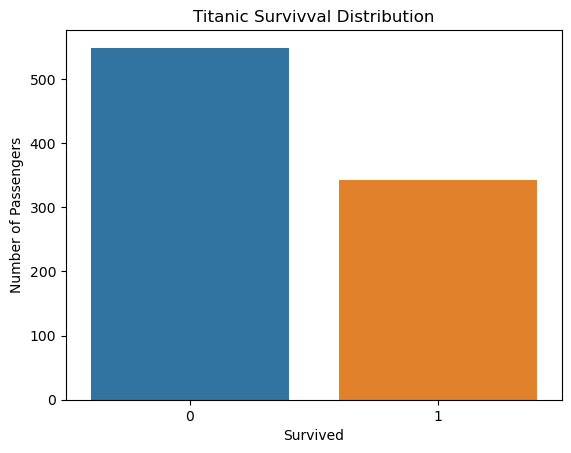

In [12]:
sns.countplot(data=df, x="survived")

plt.title("Titanic Survivval Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")
plt.show()

In [13]:
# Section 5: SELECT FEATURE AND TARGET

features = [
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked"
]

X = df[features]
y = df["survived"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   pclass     sex   age  sibsp  parch     fare embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target values:
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


In [14]:
# Section 6: IDENTIFY FEATURE TYPES

numeric_features = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

categorical_features = [
    "sex",
    "embarked"
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['pclass', 'age', 'sibsp', 'parch', 'fare']
Categorical features: ['sex', 'embarked']


In [15]:
# SECTION 7: TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training input shape:", X_train.shape)
print("Testing input shape", y_train.shape)

print("\nTraining target distribution:",y_train.value_counts(normalize=True))
print("\Testing target distribution:",y_test.value_counts(normalize=True))

Training input shape: (712, 7)
Testing input shape (712,)

Training target distribution: survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64
\Testing target distribution: survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [22]:
# SECTION 8: NUMERICAL PREPROCESSING

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# SECTION 9: CATEGORICAL PREPROCESSING

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# SECTION 10: COLUMN TRANSFORMER

preprocesser = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [44]:
# SECTION 11: CREATE RANDOM FOREST

random_forest = RandomForestClassifier(

    # NUMBER OF DESION TREES
    n_estimators = 200,

    # CRIRERION USED TO EVALUATE A SPLIT
    criterion = "gini",

    # MAXIMUM DEPTH OF EACH TREE
    # NONE MEANS TREES CAN CONTINUE GROWING
    # UNTIL OTHER STOPPING CONDITIONS ARE REACHED
    max_depth = None,

    # MINIMUM NUMBER OF SAMPLES REQUIRED
    # TO SPLUT AN INTERNAL NOED
    min_samples_split = 2,

    # MINIMUM NUMBER OF SAMPLES REQUIRED
    # IN A LEAF NODE
    min_samples_leaf = 2,

    # NUMBER OF FEATURES CONSIDERED AT EACH SPLIT
    # SQRT IS A COMMON CHOICE FOR CLASSIFICATION
    max_features = "sqrt",

    # USE BOOTSTRAP SAPMLES TO TRAIN TREES
    bootstrap = True,

    # MAKES RANDOM OPERATIONS REPRODUCIBLE
    random_state = 42,
)

In [29]:
# SECTION 12: COMPLETE PIPELINE

model = Pipeline([
    ("preprocessor", preprocesser),
    ("classifier", random_forest)
])

In [30]:
# SECTION 13: TRAIN THE MODEL

model.fit(X_train, y_train)
print("Random form=est training completed.")

Random form=est training completed.


In [32]:
# SECTION 14: MAKE PREDICTION

y_pred = model.predict(X_test)

print("Predicted values:")
print(y_pred[:20])

Predicted values:
[0 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1]


In [33]:
# SECTION 15: PREDICTION PROBABILITIES

y_probability = model.predict_proba(X_test)
print(y_probability[:10])

[[0.88754099 0.11245901]
 [0.86961828 0.13038172]
 [0.85859999 0.14140001]
 [0.95744138 0.04255862]
 [0.26412298 0.73587702]
 [0.65948734 0.34051266]
 [0.06541628 0.93458372]
 [0.3142704  0.6857296 ]
 [0.55127963 0.44872037]
 [0.83985466 0.16014534]]


In [34]:
# SECTION 16: ACCURACY

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy: ", accuracy)
print("Accuracy (%): ", accuracy * 100)

Accuracy:  0.8100558659217877
Accuracy (%):  81.00558659217877


In [35]:
# SECTION 17: CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[101   9]
 [ 25  44]]


In [36]:
# SECTION 18: CLASSIFICATION REPORT

print(
    classification_report(
        y_test,
        y_pred,
        target_names = [
            "Did Not Survive",
            "Survived"
        ],
        zero_division = 0
    )
)

                 precision    recall  f1-score   support

Did Not Survive       0.80      0.92      0.86       110
       Survived       0.83      0.64      0.72        69

       accuracy                           0.81       179
      macro avg       0.82      0.78      0.79       179
   weighted avg       0.81      0.81      0.80       179



In [39]:
# SECTION 19: FEATURE IMPORTANCE

trained_forest = model.named_steps["classifier"]
trained_preprocessor = model.named_steps["preprocessor"]

feature_names = trained_preprocessor.get_feature_names_out()
importance_values = trained_forest.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    by = "Importance",
    ascending = False
)

print(importance_df)

                   Feature  Importance
4            numeric__fare    0.216440
6    categorical__sex_male    0.198799
1             numeric__age    0.184930
5  categorical__sex_female    0.180613
0          numeric__pclass    0.108826
2           numeric__sibsp    0.039524
3           numeric__parch    0.033018
9  categorical__embarked_S    0.018111
7  categorical__embarked_C    0.012547
8  categorical__embarked_Q    0.007192


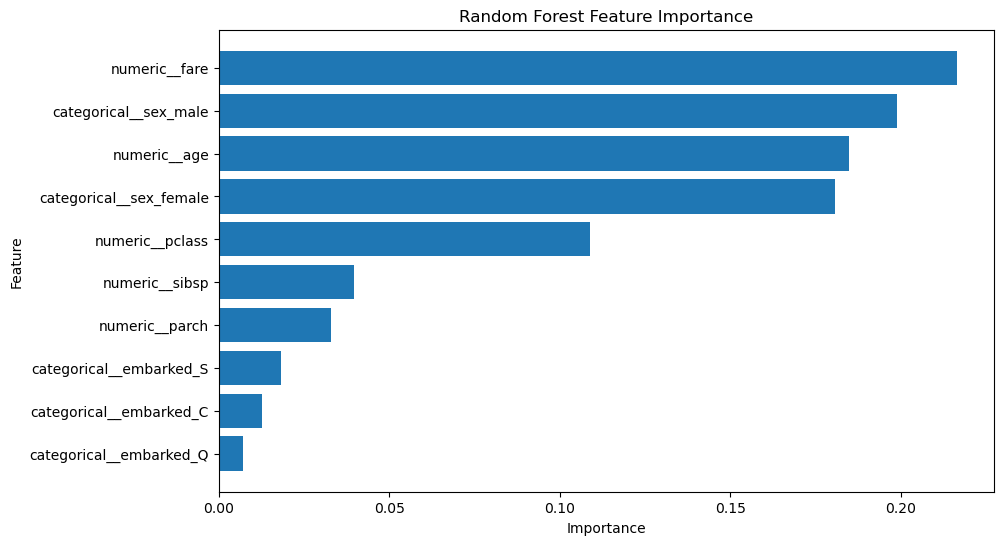

In [41]:
# SECTION 20: FEATURE IMPORTANCE PLOT

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.show()

In [43]:
# SECTION 21: PREDICT A NEW PASSENGER

new_passenger = pd.DataFrame({
    "pclass": [3],
    "sex": ["male"],
    "age": [25],
    "sibsp": [0],
    "parch": [0],
    "fare": [7.2],
    "embarked": ["S"]
})

prediction = model.predict(new_passenger)
probability = model.predict_proba(new_passenger)

print("Prediction: ", prediction[0])

print("Probability of Did Not Survive: ", probability[0][0])
print("Probability of Survived: ", probability[0][1])

Prediction:  0
Probability of Did Not Survive:  0.9210782848700337
Probability of Survived:  0.0789217151299662
